In [ ]:
!pip install pydot
!apt-get install -y graphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
import os, cv2, random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tqdm import tqdm
from random import shuffle
from IPython.display import SVG
from tensorflow.keras.utils import model_to_dot, plot_model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D

%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/dogs-cats-database/processed/'
os.makedirs(SAVE_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
TEST_SIZE = 0.5
RANDOM_STATE = 2018
BATCH_SIZE = 32
NO_EPOCHS = 20
NUM_CLASSES = 2
SAMPLE_SIZE = 7000
IMG_SIZE = 224 # Changed to 224 to align with ResNet50 input requirements


PATH = '/content/drive/MyDrive/dogs-cats-database/'
TRAIN_FOLDER = PATH + 'training_set/'
TEST_FOLDER = PATH + 'test_set/'


In [ ]:
import os, cv2, random
import numpy as np
from tqdm import tqdm
from random import shuffle

def get_image_list(folder):
    image_list = []
    for label_folder in os.listdir(folder):
        sub_path = os.path.join(folder, label_folder)
        if os.path.isdir(sub_path):
            for fname in os.listdir(sub_path):
                image_list.append(os.path.join(label_folder, fname))
    return image_list

train_image_list = get_image_list(TRAIN_FOLDER)
# For test images, assume they are directly in TEST_FOLDER, not in subfolders.
test_image_list  = os.listdir(TEST_FOLDER)

print(len(train_image_list), len(test_image_list))

def label_pet_image_one_hot_encoder(img):
    # Extract the label from the folder name, e.g., 'cats/cat.123.jpg' -> 'cats'
    label_folder = img.split('/')[0]
    if label_folder == 'cats':
        return [1, 0]
    elif label_folder == 'dogs':
        return [0, 1]
    return None

def process_data(data_image_list, DATA_FOLDER, isTrain=True):
    data_df = []
    for img in tqdm(data_image_list):
        path = os.path.join(DATA_FOLDER, img)
        label = None
        if(isTrain):
            label = label_pet_image_one_hot_encoder(img)
            # Add this check to skip images with unidentifiable labels during training
            if label is None:
                continue
        else:
            # For test images, if no label is directly available, we can use the filename as an identifier.
            # Assuming test image names are like 'id.jpg'
            label = img.split('.')[0]

        img_data = cv2.imread(path, cv2.IMREAD_COLOR)


        if img_data is None:
            print(f"Bỏ qua ảnh lỗi: {path}")
            continue

        img_data = cv2.resize(img_data, (IMG_SIZE, IMG_SIZE))
        data_df.append([np.array(img_data), np.array(label)])
    shuffle(data_df)
    return data_df

train = process_data(train_image_list, TRAIN_FOLDER, isTrain=True)
test  = process_data(test_image_list, TEST_FOLDER, isTrain=False)

6471 200


 31%|███▏      | 2025/6471 [00:47<00:20, 221.55it/s]

Bỏ qua ảnh lỗi: /content/drive/MyDrive/dogs-cats-database/training_set/cats/_DS_Store


100%|█████████▉| 6455/6471 [25:01<00:04,  3.61it/s]

Bỏ qua ảnh lỗi: /content/drive/MyDrive/dogs-cats-database/training_set/dogs/_DS_Store


100%|██████████| 200/200 [01:15<00:00,  2.64it/s]


In [ ]:
def plot_image_list_count(data_image_list):
    labels = []
    for img in data_image_list:

        label_folder = img.split('/')[0]
        labels.append(label_folder)

    sns.countplot(x=labels)
    plt.title('Cats and Dogs')
    plt.show()

In [ ]:

X = np.array([i[0] for i in train]).reshape(-1, IMG_SIZE, IMG_SIZE, 3)
y = np.array([i[1] for i in train])


X_test   = np.array([i[0] for i in test]).reshape(-1, IMG_SIZE, IMG_SIZE, 3)
ids_test = np.array([i[1] for i in test])


np.save(SAVE_DIR + 'X.npy', X)
np.save(SAVE_DIR + 'y.npy', y)
np.save(SAVE_DIR + 'X_test.npy', X_test)
np.save(SAVE_DIR + 'ids_test.npy', ids_test)

In [ ]:
model = Sequential()
model.add(ResNet50(
    include_top=False,
    pooling='max',
    weights='imagenet',              # sửa: dùng weights='imagenet' thay vì file path Kaggle
    input_shape=(IMG_SIZE, IMG_SIZE, 3)   # thêm: bắt buộc phải khai báo khi include_top=False
))
model.add(Dense(NUM_CLASSES, activation='softmax'))


model.layers[0].trainable = False

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,591,810 (90.00 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

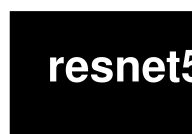

In [ ]:
model.summary()
plot_model(model, to_file='model.png', show_shapes=True)  # thêm show_shapes=True cho dễ nhìn
SVG(model_to_dot(model).create(prog='dot', format='svg'))

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [ ]:
train_model = model.fit(X_train, y_train,
                  batch_size=BATCH_SIZE,
                  epochs=NO_EPOCHS,
                  verbose=1,
                  validation_data=(X_val, y_val))

Epoch 1/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1143s 11s/step - accuracy: 0.9038 - loss: 0.7428 - val_accuracy: 0.9413 - val_loss: 0.3679
Epoch 2/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1120s 11s/step - accuracy: 0.9709 - loss: 0.1677 - val_accuracy: 0.9645 - val_loss: 0.2341
Epoch 3/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1117s 11s/step - accuracy: 0.9814 - loss: 0.0914 - val_accuracy: 0.9685 - val_loss: 0.2170
Epoch 4/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1154s 11s/step - accuracy: 0.9787 - loss: 0.1313 - val_accuracy: 0.9787 - val_loss: 0.1432
Epoch 5/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1114s 11s/step - accuracy: 0.9926 - loss: 0.0313 - val_accuracy: 0.9777 - val_loss: 0.1389
Epoch 6/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1159s 11s/step - accuracy: 0.9960 - loss: 0.0108 - val_accuracy: 0.9784 - val_loss: 0.1493
Epoch 7/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1255s 12s/step - accuracy: 0.9978 - loss: 0.0056 - val_accuracy: 0.9790 - val_loss: 0.1434
Epoch 8/20
102/102 ━━━━━━━━━━━━━━━━━━━━ 1176s 12s/step - accuracy: 0.9981 - loss: 0

In [ ]:
model.save(SAVE_DIR + 'model_final.keras')
print("Đã lưu model tại:", SAVE_DIR + 'model_final.keras')

Đã lưu model tại: /content/drive/MyDrive/dogs-cats-database/processed/model_final.keras


In [ ]:
import pickle

with open(SAVE_DIR + 'training_history.pkl', 'wb') as f:
    pickle.dump(train_model.history, f)

print("Đã lưu training history tại:", SAVE_DIR + 'training_history.pkl')

Đã lưu training history tại: /content/drive/MyDrive/dogs-cats-database/processed/training_history.pkl


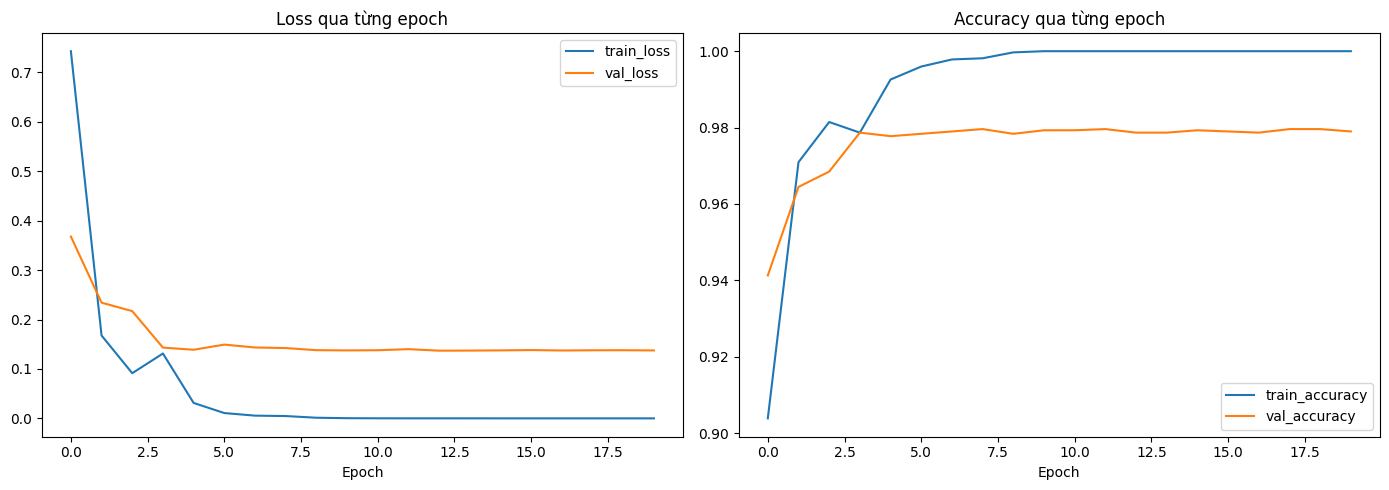

Đã lưu biểu đồ tại: /content/drive/MyDrive/dogs-cats-database/processed/training_curves.png


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(train_model.history['loss'], label='train_loss')
ax[0].plot(train_model.history['val_loss'], label='val_loss')
ax[0].set_title('Loss qua từng epoch')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(train_model.history['accuracy'], label='train_accuracy')
ax[1].plot(train_model.history['val_accuracy'], label='val_accuracy')
ax[1].set_title('Accuracy qua từng epoch')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.savefig(SAVE_DIR + 'training_curves.png', dpi=150)
plt.show()

print("Đã lưu biểu đồ tại:", SAVE_DIR + 'training_curves.png')

In [ ]:
pred_list = []
img_list = []
for img in tqdm(test):
    img_data = img[0]
    img_idx = img[1]
    input_data = img_data.reshape(-1, IMG_SIZE, IMG_SIZE, 3)
    predicted = model.predict(input_data, verbose=0)[0]   # sửa: bỏ [ ] thừa, thêm verbose=0
    img_list.append(img_idx)
    pred_list.append(predicted[1])   # predicted[1] = xác suất là "Dog" (theo one-hot [cat, dog])

100%|██████████| 200/200 [01:14<00:00,  2.70it/s]
